In [2]:
import os
import sys
import warnings as warn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import skew, kurtosis
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, mean_absolute_error, mean_squared_error, r2_score, silhouette_score


In [3]:
warn.filterwarnings('ignore')
plt.style.use('default')
sns.set_theme(style='whitegrid')

In [4]:
data_dir = "../../../../datasets/amazon_sales_data_uncleaned.csv"
exact_cols = ['Title', 'Rating', 'Number_of_reviews', 'bought_in_last_month',
       'Current/discounted_price', 'Price_on_variant', 'Listed_price',
       'is_best_seller', 'is_sponsored', 'is_couponed', 'buy_box_availability',
       'delivery_details', 'sustainability_badges', 'image_url', 'product_url',
       'collected_at']
target_col = None


In [5]:
try: 
    df = pd.read_csv(data_dir)
except Exception as e:
    print(f"Error loading CSV from {data_dir}: {e}")
    df = pd.DataFrame()

In [6]:
if not df.empty and exact_cols:
    missing_cols = set(exact_cols) - set(df.columns)
    extra_cols = set(df.columns) - set(exact_cols)
    if missing_cols:
        print(f"Missing expected columns: {missing_cols}")
    if extra_cols:
        print(f"Extra columns found: {extra_cols}")
    else:
        print(f"No extra and missing columns was found")

No extra and missing columns was found


In [7]:
print("==== Data Audit ====")
print(f"Dataset Shape; {df.shape}")
print("\nData Types:\n", df.dtypes)
print("\nNull Values:\n", df.isnull().sum())
print(f"\nDuplicate Rows: {df.duplicated().sum()}")
print("\nCardinality (Unique Values): \n", df.nunique())

inf_mask = np.isinf(
    df.select_dtypes(include=[np.number])
) if not df.empty else pd.DataFrame()

print("\nInfinite Values Count:\n", inf_mask.sum()
      if not inf_mask.empty else 0)

==== Data Audit ====
Dataset Shape; (42675, 16)

Data Types:
 Title                       object
Rating                      object
Number_of_reviews           object
bought_in_last_month        object
Current/discounted_price    object
Price_on_variant            object
Listed_price                object
is_best_seller              object
is_sponsored                object
is_couponed                 object
buy_box_availability        object
delivery_details            object
sustainability_badges       object
image_url                   object
product_url                 object
collected_at                object
dtype: object

Null Values:
 Title                           0
Rating                       1024
Number_of_reviews            1024
bought_in_last_month         3217
Current/discounted_price    11749
Price_on_variant                0
Listed_price                    0
is_best_seller                  0
is_sponsored                    0
is_couponed                     0
buy_box_a

In [8]:
df_clean = df.copy()

if not df_clean.empty:
    for col in df_clean.select_dtypes(include=['object']).columns:
        df_clean[col] = df_clean[col].astype(str).str.strip()
        df_clean[col] = df_clean[col].replace({
            'nan': np.nan,
            'None': np.nan,
            '': np.nan
        })

    for col in df_clean.columns:
        if 'date' in col.lower() or 'at' in col.lower():
            try:
                df_clean[col] = pd.to_datetime(df_clean[col], errors='ignore')
            except Exception:
                pass

    df_clean = df_clean.drop_duplicates()

    num_cols = df_clean.select_dtypes(include=[np.number]).columns.tolist()
    cat_cols = df_clean.select_dtypes(include=['object', 'category']).columns.tolist()
    

    for col in df_clean.columns:
        if df_clean[col].isnull().sum() > 0:
            df_clean[f"{col}__was_missing"] = df_clean[col].isnull().astype(int)


    for col in num_cols:
        if df_clean[col].isnull().sum() > 0:
            df_clean[col] = df_clean[col].fillna(df_clean[col].median())


    for col in cat_cols:
        if df_clean[col].isnull().sum() > 0:
            df_clean[col] = df_clean[col].fillna("Missing")


    for col in num_cols:
        quan_1 =  df_clean[col].quantile(0.25)
        quan_3 =  df_clean[col].quantile(0.75)

        int_quar = quan_3 - quan_1
        lower_bound = quan_1 - 1.5 * int_quar
        upper_bound = quan_3 + 1.5 * int_quar

        df_clean[f"{col}__winsor"] = np.clip(df_clean[col], lower_bound, upper_bound)



In [9]:
print("\n==== NUMERIC SUMMARY ====")
num_clean_cols = df_clean.select_dtypes(
    include=[np.number]
).columns.tolist()

if num_clean_cols:
    num_summary = pd.DataFrame({
        'mean': df_clean[num_clean_cols].mean(),
        'std': df_clean[num_clean_cols].std(),
        'skew': df_clean[num_clean_cols].apply(lambda x : skew(x.dropna())),
        'kurtosis': df_clean[num_clean_cols].apply(lambda x: kurtosis(x.dropna()))
    })
    print(num_summary)


==== NUMERIC SUMMARY ====
                                           mean       std      skew   kurtosis
Rating__was_missing                    0.024549  0.154747  6.144959  35.760518
Number_of_reviews__was_missing         0.024549  0.154747  6.144959  35.760518
bought_in_last_month__was_missing      0.077122  0.266789  3.170173   8.049995
Current/discounted_price__was_missing  0.277803  0.447921  0.992137  -1.015664
buy_box_availability__was_missing      0.347422  0.476157  0.640882  -1.589270
delivery_details__was_missing          0.277108  0.447576  0.996010  -1.007965
sustainability_badges__was_missing     0.918299  0.273912 -3.054292   7.328700
product_url__was_missing               0.026538  0.160732  5.891382  32.708382


==== NUMERIC SUMMARY GRAPH ====


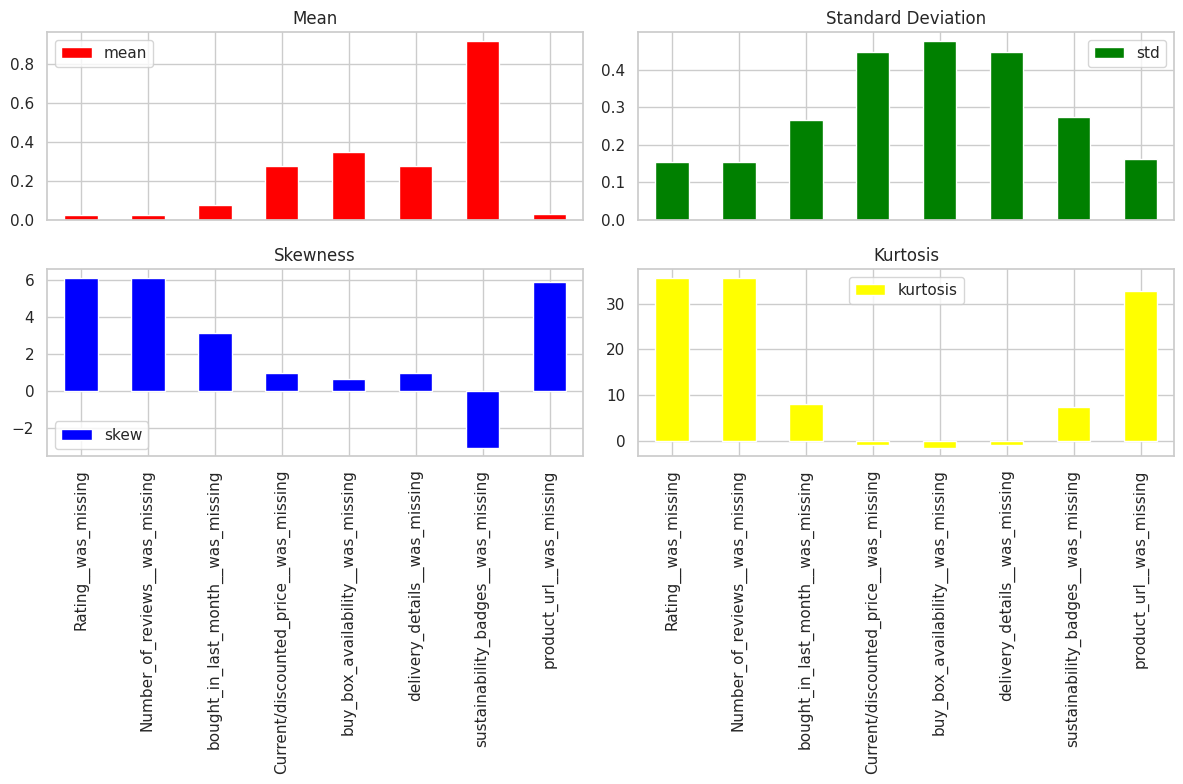

In [10]:
num_summary.plot(
    kind='bar',
    subplots=True,
    layout=(2,2),
    figsize=(12, 8),
    color=['red', 'green', 'blue', 'yellow'],
    title=['Mean', 'Standard Deviation', 'Skewness', 'Kurtosis']
)
print("==== NUMERIC SUMMARY GRAPH ====")
plt.tight_layout()
plt.show()

In [11]:
print("\n==== CATEGORIAL FREQUENCY TABLES ====")
cat_clean_cols = df_clean.select_dtypes(
    include=['object', 'category']
).columns.tolist()

for col in cat_clean_cols[:5]:
    print(f"\nFrequency table for {col}: ")
    print(df_clean[col].value_counts().head(5))

if len(num_clean_cols) > 1:
    pearson_corr = df_clean[num_clean_cols].corr(method='pearson')
    spearman_corr = df_clean[num_clean_cols].corr(method='spearman')

    print("\n==== HIGH CORRELATION PAIRS (>0.85) ====")
    for i in range(len(num_clean_cols)):
        for j in range(i + 1, len(num_clean_cols)):
            col1, col2 = num_clean_cols[i], num_clean_cols[j]
            r = pearson_corr.loc[col1, col2]

            if abs(r) > 0.85:
                print(f"High Pearson r: {col1} & {col2} = {r:.4f}")


==== CATEGORIAL FREQUENCY TABLES ====

Frequency table for Title: 
Title
TRX Training 6 Month On-Demand Membership - Unlimited Access to Expert-Led Workouts, Personalized Programs, Strength, Cardio & Recovery - Train Anytime                                          456
KODAK 10.1 Inch WiFi Digital Picture Frame,1280x800 HD IPS Touch Screen, Electronic Smart Photo Frame with 32 GB Memory, Auto-Rotate, Instantly Share Photos/Videos Anywhere                     438
Duracell Coppertop 9V Battery, 6 Count (Pack of 1), 9 Volt Battery with Long-lasting Power, All-Purpose Alkaline 9V Battery for Household and Office Devices                                     390
Belkin MagSafe-Compatible Charger, 3-in-1 Wireless Charging Station, Qi2-Certified 15W Wireless Charge for Apple iPhone 16 Series, Apple Watch, AirPods w/Non-Slip Base, 40W Included - Black    377
RCA 10.1" WiFi Digital Picture Frame Uhale App Photo Frames Electronic HD IPS Touch Screen Display with 32GB Memory LED Lights, Support US

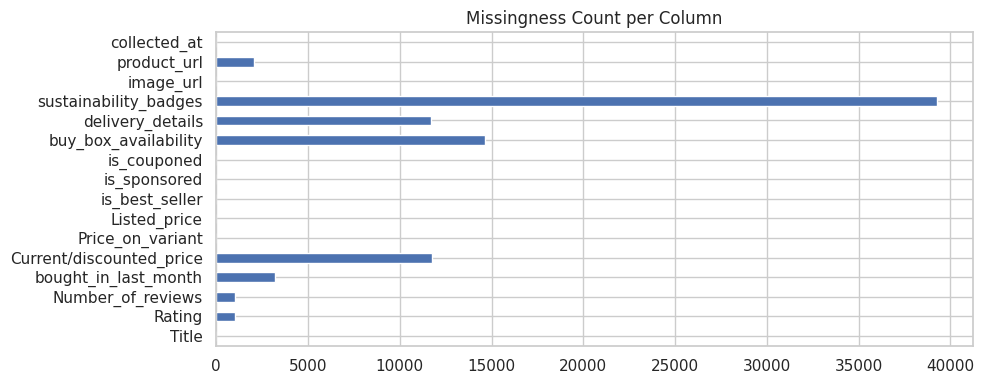

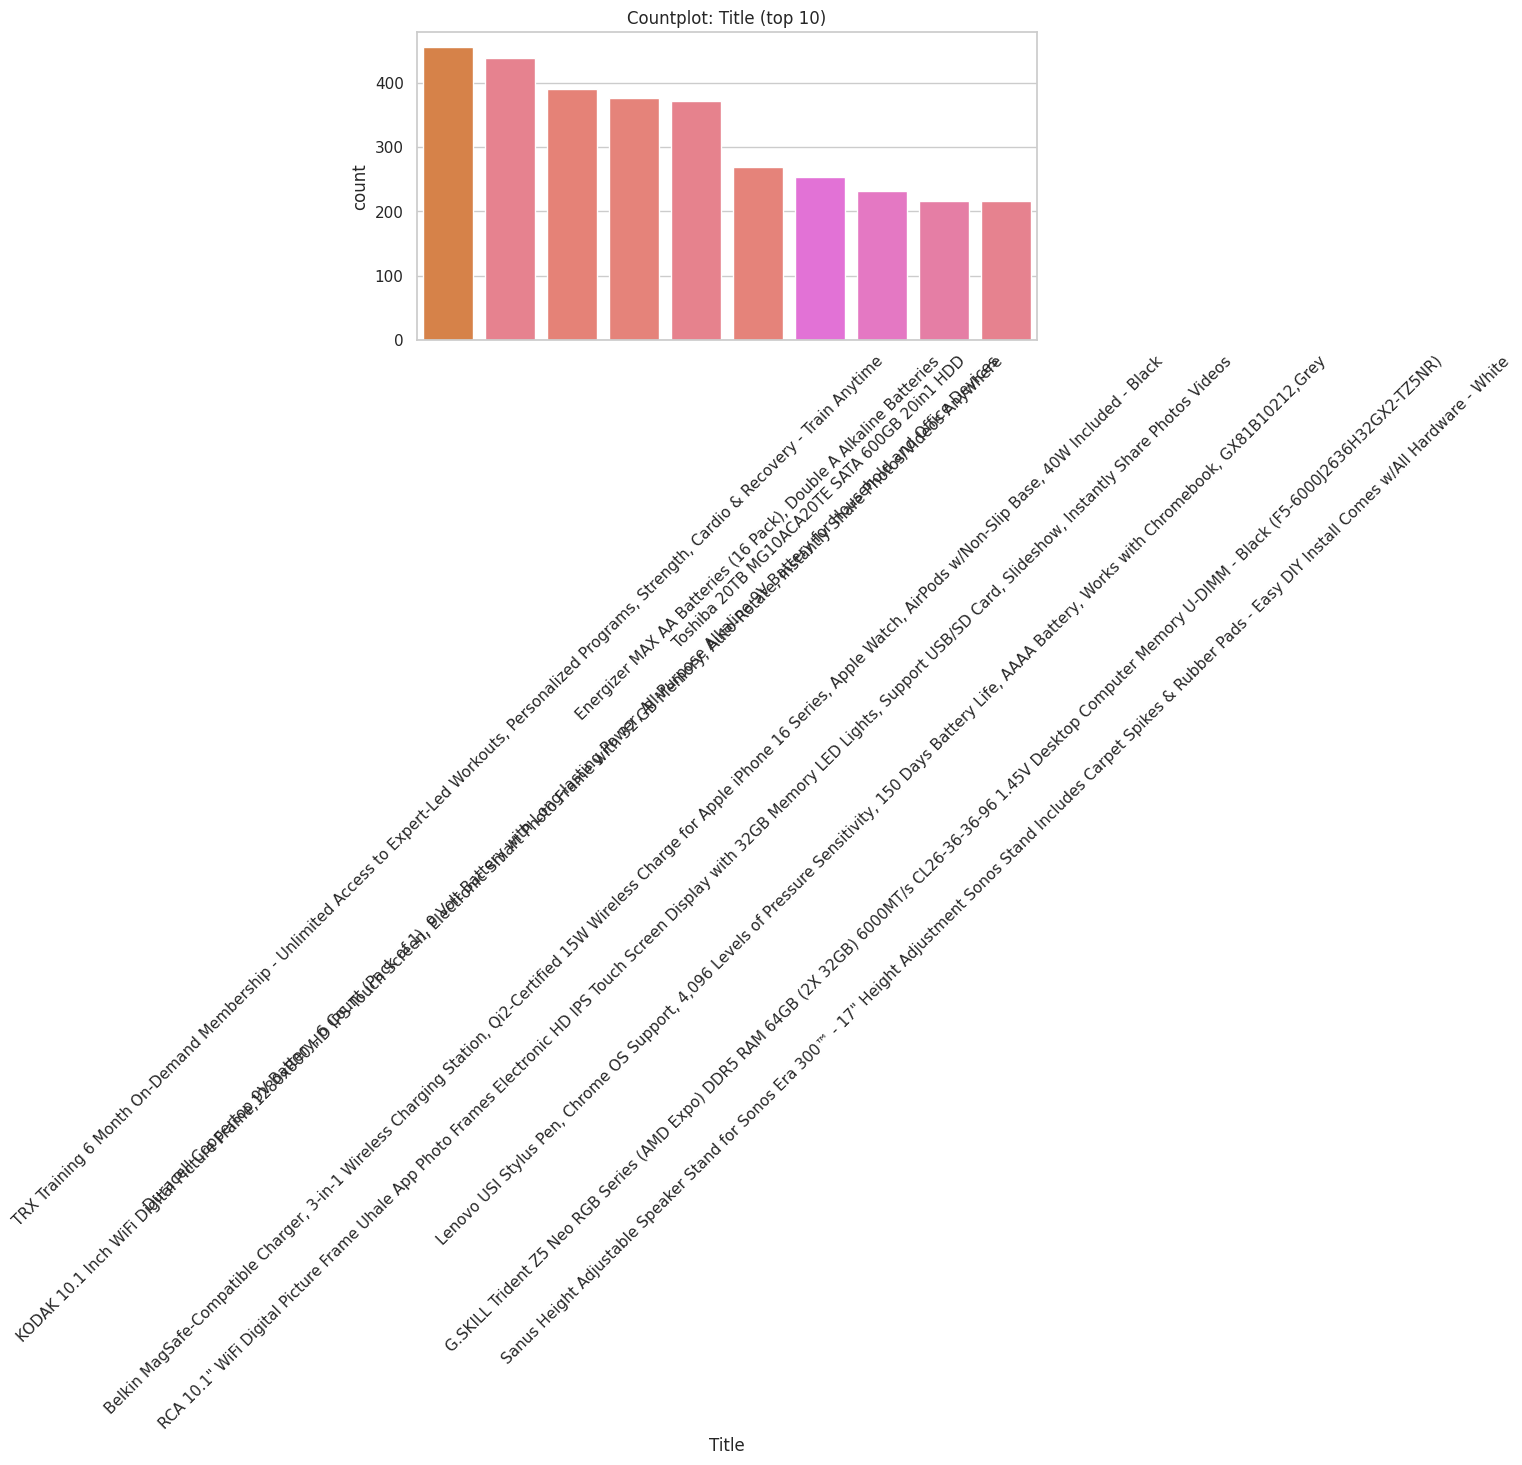

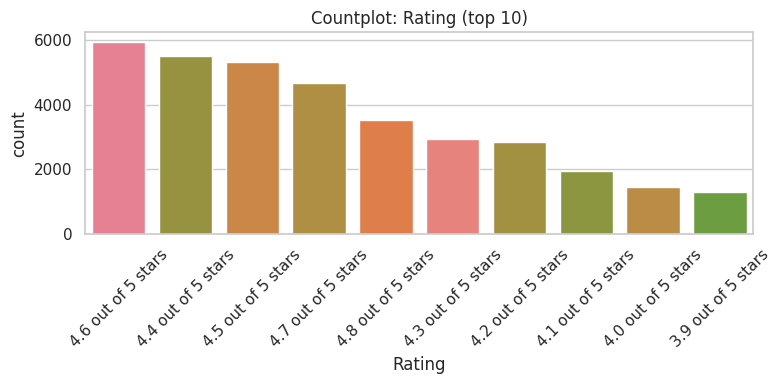

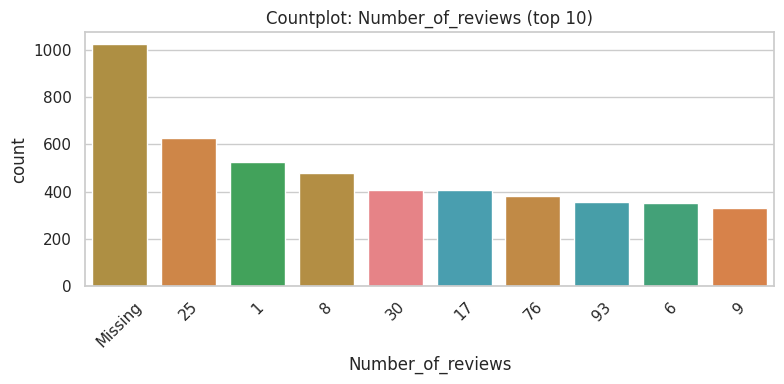

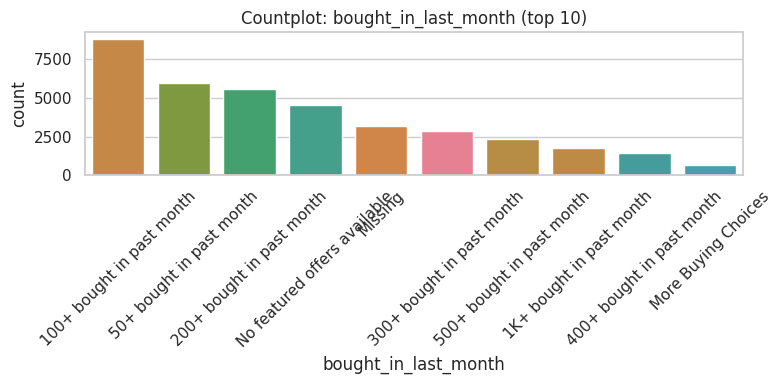

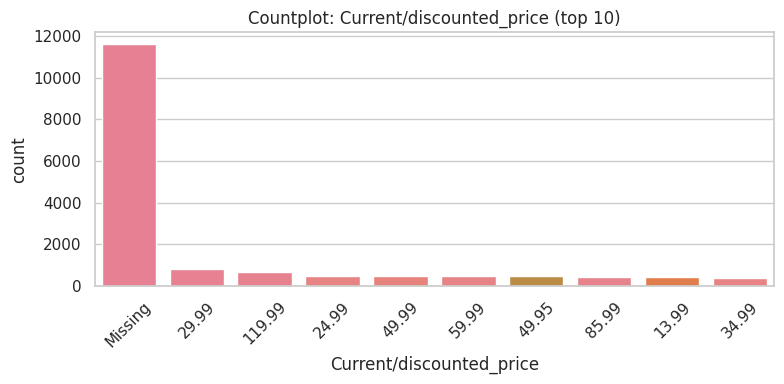

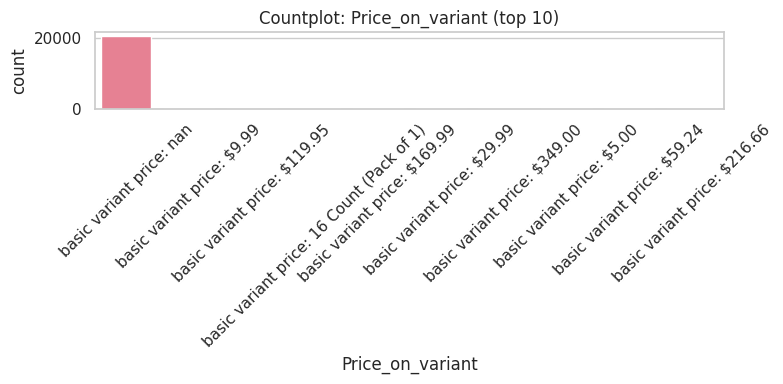

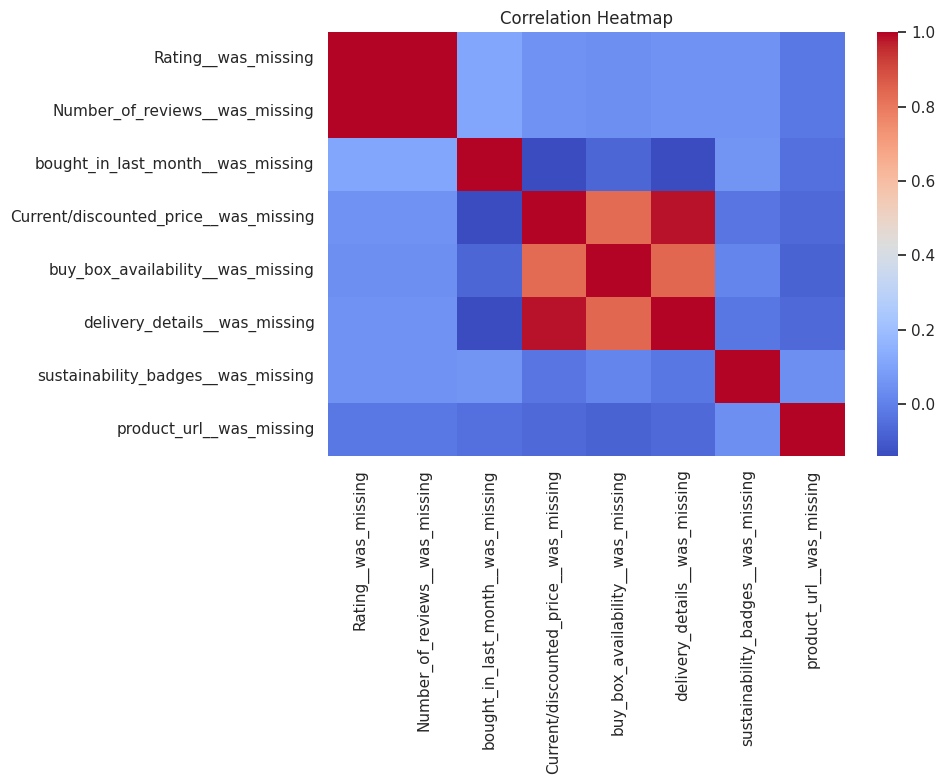

In [12]:
if df.isnull().sum().sum() > 0:
    plt.figure(figsize=(10,4))
    df.isnull().sum().plot(kind='barh')
    plt.title("Missingness Count per Column")
    plt.tight_layout()
    plt.show()

plot_num_cols = [c for c in num_cols if not c.endswith('__winsor') and not c.endswith('__was_missing')][:12]

if plot_num_cols:
    df_clean[plot_num_cols].hist(figsize=(12, 18), bins=20)
    plt.suptitle("Histograms")
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(12, 6))
    sns.boxplot(data=df_clean[plot_num_cols])
    plt.title("Boxplots")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

plot_cat_cols = cat_clean_cols[:6]

for c in plot_cat_cols:
    plt.figure(figsize=(8,4))
    sns.countplot(
        data=df_clean,
        x=c,
        order=df_clean[c].value_counts().index[:10],
        hue=c,
        legend=False
    )
    plt.title(f"Countplot: {c} (top 10)")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

if len(num_clean_cols) > 1:
    plt.figure(figsize=(10, 8))
    sns.heatmap(pearson_corr, annot=False, cmap='coolwarm')
    plt.title("Correlation Heatmap")
    plt.tight_layout()
    plt.show()


In [13]:
dt_cols = df_clean.select_dtypes(
    include=['datetime', 'datetime64']
).columns.tolist()

for col in dt_cols:
    df_clean[f"{col}__year"] = df_clean[col].dt.year
    df_clean[f"{col}__month"] = df_clean[col].dt.month
    df_clean[f"{col}__dayofweek"] = df_clean[col].dt.dayofweek

obj_cols = df_clean.select_dtypes(
    include=['object']
).columns.tolist()

for col in obj_cols:
    df_clean[f"{col}__len"] = df_clean[col].astype(str).str.len()
    df_clean[f"{col}__words"] = df_clean[col].astype(str).str.split().str.len()
    

In [14]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 41713 entries, 0 to 42674
Data columns (total 57 columns):
 #   Column                                 Non-Null Count  Dtype         
---  ------                                 --------------  -----         
 0   Title                                  41713 non-null  object        
 1   Rating                                 41713 non-null  object        
 2   Number_of_reviews                      41713 non-null  object        
 3   bought_in_last_month                   41713 non-null  object        
 4   Current/discounted_price               41713 non-null  object        
 5   Price_on_variant                       41713 non-null  object        
 6   Listed_price                           41713 non-null  object        
 7   is_best_seller                         41713 non-null  object        
 8   is_sponsored                           41713 non-null  object        
 9   is_couponed                            41713 non-null  object     

In [23]:
df_clean.loc[0]

Title                                    BOYA BOYALINK 2 Wireless Lavalier Microphone f...
Rating                                                                  4.6 out of 5 stars
Number_of_reviews                                                                      375
bought_in_last_month                                             300+ bought in past month
Current/discounted_price                                                             89.68
Price_on_variant                                               basic variant price: 2.4GHz
Listed_price                                                                       $159.00
is_best_seller                                                                    No Badge
is_sponsored                                                                     Sponsored
is_couponed                                                          Save 15%  with coupon
buy_box_availability                                                           Add to cart

In [36]:
for col in df_clean.columns[:16]:
    print(f"{col} with there different Value counts: \n")
    print(df_clean[col].value_counts())

Title with there different Value counts: 

Title
TRX Training 6 Month On-Demand Membership - Unlimited Access to Expert-Led Workouts, Personalized Programs, Strength, Cardio & Recovery - Train Anytime                                          456
KODAK 10.1 Inch WiFi Digital Picture Frame,1280x800 HD IPS Touch Screen, Electronic Smart Photo Frame with 32 GB Memory, Auto-Rotate, Instantly Share Photos/Videos Anywhere                     438
Duracell Coppertop 9V Battery, 6 Count (Pack of 1), 9 Volt Battery with Long-lasting Power, All-Purpose Alkaline 9V Battery for Household and Office Devices                                     390
Belkin MagSafe-Compatible Charger, 3-in-1 Wireless Charging Station, Qi2-Certified 15W Wireless Charge for Apple iPhone 16 Series, Apple Watch, AirPods w/Non-Slip Base, 40W Included - Black    377
RCA 10.1" WiFi Digital Picture Frame Uhale App Photo Frames Electronic HD IPS Touch Screen Display with 32GB Memory LED Lights, Support USB/SD Card, Slideshow, Ins

In [31]:
target_col = None

In [40]:
problem_type = "unsupervised"
if target_col and target_col in df_clean.columns:
    target_series = df_clean[target_col]
    if target_series.dtype == 'object' or target_series.dtype.name == 'category' or target_series.dtype == 'bool':
        problem_type = 'classification'

    elif np.issubdtype(target_series.dtype, np.number):
        if target_series.nunique() <= 15:
            problem_type = 'classification'
        else:
            problem_type = 'regression'

print(f"\nDetected Problem Type: {problem_type}")


Detected Problem Type: unsupervised


In [41]:
best_model = None
best_score = -np.inf if problem_type != "regression" else np.inf

feature_cols = [c for c in df_clean.columns if c != target_col and not pd.api.types.is_datetime64_any_dtype(df_clean[c])]

num_features = df_clean[feature_cols].select_dtypes(include=[np.number]).columns.tolist()

cat_features = df_clean[feature_cols].select_dtypes(include=['object', 'category']).columns.tolist()

preprocessor = ColumnTransformer(
    transformers = [
        ('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), num_features),
        ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('encoder', OneHotEncoder(handle_unknown='ignore'))]), cat_features)
    ]
)


In [58]:
best_model = None
if problem_type in ["classification", "regression"]:
    X = df_clean[feature_cols]
    y = df_clean[target_col]

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    if problem_type == 'classification':
        best_score = 0.0
        models = {
            "LogisticRegression": LogisticRegression(random_state=42),
            "KNeighborsClassifier": KNeighborsClassifier(),
            "DecisionTreeClassifier": DecisionTreeClassifier(random_state=42),
            "RandomForestClassifier": RandomForestClassifier(random_state=42, n_jobs=-1)
        }

        for name, model in models.items():
            pipe = Pipeline([
                ('prep', preprocessor),
                ('model', model)
            ])
            pipe.fit(X_train, y_train)
            preds = pipe.predict(X_test)
            acc = accuracy_score(y_test, preds, average='weighted')
            f1 = f1_score(y_test, preds)
            cm = confusion_matrix(y_test, preds)
            print(f"\nModel: {name}\nAccuracy: {acc:.4f}\nWeighted F1: {f1:.4f}\nConfusion Matrix:\n{cm}")

            if f1 > best_score:
                best_score = f1
                best_model = pipe

    elif problem_type == "regression":
        best_score = float('inf')
        models = {
            "LinearRegression": LinearRegression(),
            "KNeighborsRegressor": KNeighborsRegressor(),
            "DecisionTreeRegressor": DecisionTreeRegressor(random_state=42),
            "RandomForestRegressor": RandomForestRegressor(random_state=42)
        }

        for name, model in models.items():
            pipe = Pipeline([
                            ('prep', preprocessor),
                            ('model', model)
                        ])
            pipe.fit(X_train, y_train)
            preds = pipe.predict(X_test)
            mae = mean_absolute_error(y_test, preds)
            rsme= np.sqrt(mean_squared_error(y_test, preds))
            r2 = r2_score(y_test, preds)
            print(f"\nModel: {name}\nMAE: {mae:.4f}\nRSME: {rsme:.4f}\nR2:\n{r2}")

            if rsme < best_score:
                best_score = rsme
                best_model = pipe

else:
    X = df_clean[feature_cols]
    best_inertia = float('inf')

    X_trans = preprocessor.fit_transform(X)
    for k in range(2, 6):
        kmeans = KMeans(n_clusters=k, random_state=42, n_init='auto')
        labels = kmeans.fit_predict(X_trans)
        inertia = kmeans.inertia_
        sil_sample_size = min(X_trans.shape[0], 5000)
        
        sil = silhouette_score(X_trans[:sil_sample_size], labels[:sil_sample_size])

        print(f"KMeans (k={k}) -> Inertia: {inertia:.4f}, Silhouette Score: {sil:.4f}")

        if inertia < best_inertia:
            best_inertia = inertia
            best_model = kmeans



KMeans (k=2) -> Inertia: 1648355.5623, Silhouette Score: 0.2698
KMeans (k=3) -> Inertia: 1406291.2075, Silhouette Score: 0.2253
KMeans (k=4) -> Inertia: 1352017.0650, Silhouette Score: 0.2403
KMeans (k=5) -> Inertia: 1253927.3661, Silhouette Score: 0.1658


In [60]:
print("\n ==== FINAL SUMMARY ====")
print(f"Original Shape: {df.shape}")
print(f"Cleaned Shape: {df_clean.shape}")
print(f"Problem Type: {problem_type}")
print(f"Best Model Evaluation: {best_model}")
print("\nCleaned Data Head:")
print(df_clean.loc[0])


 ==== FINAL SUMMARY ====
Original Shape: (42675, 16)
Cleaned Shape: (41713, 57)
Problem Type: unsupervised
Best Model Evaluation: KMeans(n_clusters=5, random_state=42)

Cleaned Data Head:
Title                                    BOYA BOYALINK 2 Wireless Lavalier Microphone f...
Rating                                                                  4.6 out of 5 stars
Number_of_reviews                                                                      375
bought_in_last_month                                             300+ bought in past month
Current/discounted_price                                                             89.68
Price_on_variant                                               basic variant price: 2.4GHz
Listed_price                                                                       $159.00
is_best_seller                                                                    No Badge
is_sponsored                                                                     Sp